# Projeto: Previsão de Rotatividade de Funcionários (HR Attrition)

Projeto pessoal do MBA (disciplina de Árvores e Ensemble), usando um dataset diferente do da aula.

**Objetivo:** prever `Attrition` (Yes/No) — se o colaborador deixou a empresa — evoluindo o mesmo dataset ao longo de 2 etapas (Árvore de Decisão → Ensemble) e, ao final, interpretando o modelo escolhido com SHAP.

## 0. Setup

In [1]:
# Bibliotecas necessárias: veja o arquivo requirements.txt
# Instalação (rode no terminal, uma única vez):
#   pip install -r requirements.txt

In [2]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# --- Manipulação e visualização de dados ---
import pandas as pd
import matplotlib.pyplot as plt
import shap

# --- Separação treino/teste e validação cruzada / busca de hiperparâmetros ---
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
)

# --- Modelos ---
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
import xgboost as xgb

# --- Métricas de avaliação ---
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score,
)


## 1. Carregamento dos Dados

In [3]:
# Carrega o dataset (mantenha o CSV na mesma pasta deste notebook)
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')


## 2. Exploração Inicial

In [4]:
# Visualização inicial das primeiras linhas, com todas as colunas visíveis
pd.set_option('display.max_columns', None)
df.head()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [5]:
# Número de linhas (funcionários) e colunas (variáveis)
df.shape


(1470, 35)

In [6]:
# Tipos de dado e presença de valores nulos por coluna
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

### 2.1 Investigação das colunas "armadilha"

Colunas suspeitas de serem constantes ou de não terem valor preditivo (`EmployeeCount`, `EmployeeNumber`, `Over18`, `StandardHours`).

In [7]:
# Confirma que 'Over18' é realmente constante (só o valor 'Y' em todo o dataset)
df['Over18'].value_counts()


Over18
Y    1470
Name: count, dtype: int64

In [8]:
# Confirma que 'StandardHours' é realmente constante (só um valor único)
df['StandardHours'].unique()


array([80])

## 3. Pré-processamento

**Resumo das decisões de codificação:**

| Coluna | Tipo | Tratamento |
|---|---|---|
| `Department`, `JobRole`, `MaritalStatus`, `EducationField`, `Gender` | Nominal | `get_dummies` |
| `BusinessTravel` | Ordinal (progressão de frequência) | Mapeamento manual 0/1/2 |
| `Attrition` | Binária → variável-alvo (`y`) | Mapeamento manual 1/0 |
| `OverTime` | Binária | Mapeamento manual 1/0 |
| `EmployeeCount`, `EmployeeNumber`, `Over18`, `StandardHours` | Sem valor preditivo (constantes ou IDs) | Descartadas (`drop`) |
| `Education`, `EnvironmentSatisfaction`, `JobInvolvement`, `JobLevel`, `JobSatisfaction`, `PerformanceRating`, `RelationshipSatisfaction`, `StockOptionLevel`, `WorkLifeBalance` | Ordinal (já numéricas) | Mantidas como estão |

### 3.1 Codificação das variáveis nominais (`get_dummies`)

In [9]:
# Codifica as variáveis categóricas nominais em colunas binárias (0/1)
df_encoded = pd.get_dummies(
    df,
    columns=['Department', 'JobRole', 'MaritalStatus', 'EducationField', 'Gender'],
    dtype=int
)


### 3.2 Mapeamento manual das variáveis ordinais/binárias

In [10]:
# BusinessTravel: ordinal (progressão de frequência de viagem)
mapeamento_viagem = {
    'Non-Travel': 0,
    'Travel_Rarely': 1,
    'Travel_Frequently': 2
}
df_encoded['BusinessTravel'] = df_encoded['BusinessTravel'].map(mapeamento_viagem)

In [11]:
# Attrition: variável-alvo binária
df_encoded['Attrition'] = df_encoded['Attrition'].map({'Yes': 1, 'No': 0})

In [12]:
# OverTime: binária
df_encoded['OverTime'] = df_encoded['OverTime'].map({'Yes': 1, 'No': 0})

### 3.3 Descarte das colunas sem valor preditivo

In [13]:
# Separa variáveis explicativas (X) e variável-alvo (y)
# Descarta também as colunas "armadilha" sem valor preditivo (constantes / ID)
X = df_encoded.drop(['Attrition', 'StandardHours', 'Over18', 'EmployeeCount', 'EmployeeNumber'], axis=1)
y = df_encoded['Attrition']


### 3.4 Checagem final do pré-processamento

In [14]:
# Nenhuma coluna deve restar como texto (object) dentro de X
X.dtypes[X.dtypes == 'object']

Series([], dtype: object)

In [15]:
# Confirma o número final de colunas em X, após codificação e descarte
X.shape


(1470, 48)

In [16]:
# Confirma o desbalanceamento das classes -> vai ser retomado na seção 5.4
y.value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64

## 4. Separação Treino/Teste

In [17]:
# Separação treino/teste, preservando a proporção original das classes (stratify=y)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, stratify=y, random_state=42
)


## 5. Árvore de Decisão

In [18]:
# Árvore de decisão sem nenhuma restrição de profundidade (baseline)
modelo_arvore = DecisionTreeClassifier(random_state=5389)
modelo_arvore.fit(X_treino, y_treino)

predicoes_treino = modelo_arvore.predict(X_treino)
predicoes = modelo_arvore.predict(X_teste)


### 5.1 Avaliação do modelo base

Comparação entre `predict` (classe final) e `predict_proba` (probabilidade de cada classe) para as primeiras linhas do teste.

In [19]:
# Compara a classe prevista (predict) com a probabilidade de cada classe (predict_proba)
probabilidades = modelo_arvore.predict_proba(X_teste)

comparacao = pd.DataFrame({
    'predicao (classe)': predicoes[:10],
    'prob_classe_0': probabilidades[:10, 0],
    'prob_classe_1': probabilidades[:10, 1],
})
comparacao


,predicao (classe),prob_classe_0,prob_classe_1
0,0,1.0,0.0
1,0,1.0,0.0
2,0,1.0,0.0
3,0,1.0,0.0
4,0,1.0,0.0
5,0,1.0,0.0
6,0,1.0,0.0
7,0,1.0,0.0
8,0,1.0,0.0
9,0,1.0,0.0


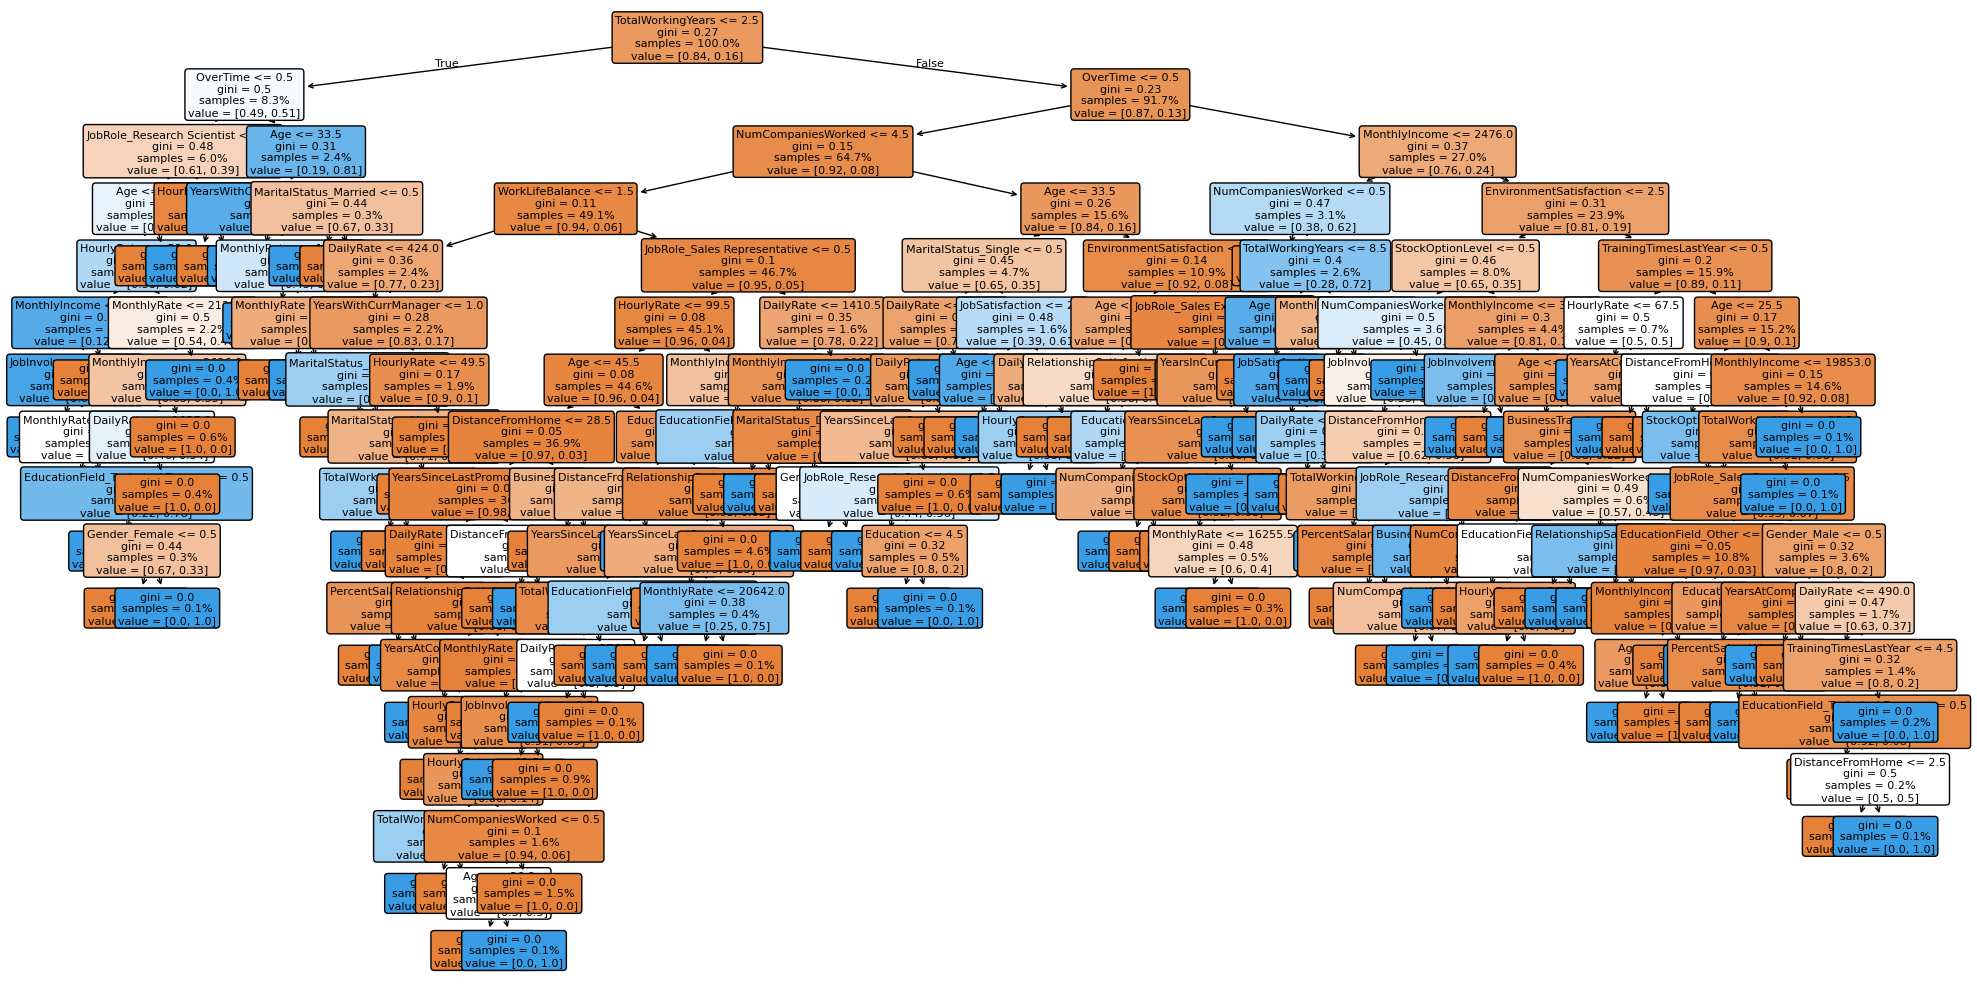

In [20]:
# Visualização da árvore completa (sem poda)
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_arvore,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8,
    proportion=True,
    precision=2,
)
plt.tight_layout()
plt.show()


In [21]:
# Acurácia no treino vs. teste -> overfitting evidente sem poda
acuracia_treino = accuracy_score(y_treino, predicoes_treino)
acuracia_teste = accuracy_score(y_teste, predicoes)

print(f'Acurácia nos dados de treino: {acuracia_treino:.2%}')
print(f'Acurácia nos dados de teste: {acuracia_teste:.2%}')


Acurácia nos dados de treino: 100.00%
Acurácia nos dados de teste: 75.27%


In [22]:
# Precisão, recall e F1 por classe
relatorio = classification_report(y_teste, predicoes)
print(relatorio)


              precision    recall  f1-score   support

           0       0.86      0.84      0.85       309
           1       0.26      0.29      0.27        59

    accuracy                           0.75       368
   macro avg       0.56      0.56      0.56       368
weighted avg       0.76      0.75      0.76       368



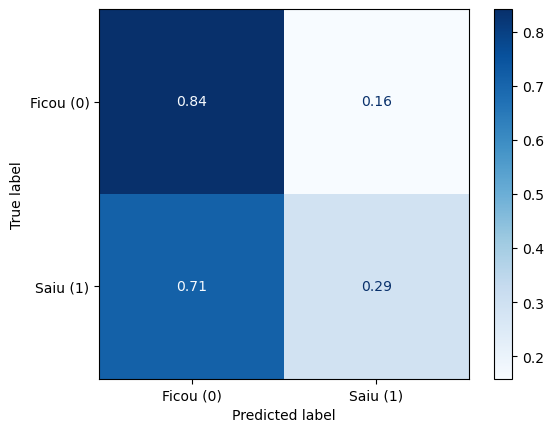

In [23]:
# Matriz de confusão normalizada por linha (taxa de acerto por classe real)
ConfusionMatrixDisplay.from_estimator(
    modelo_arvore, X_teste, y_teste,
    normalize='true',
    cmap='Blues',
    display_labels=['Ficou (0)', 'Saiu (1)']
);


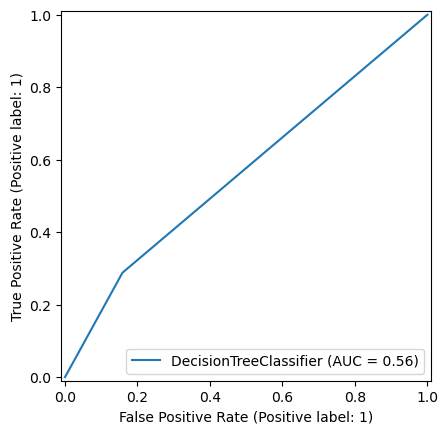

In [24]:
# Curva ROC do modelo sem poda
RocCurveDisplay.from_estimator(modelo_arvore, X_teste, y_teste);


### 5.2 Poda para reduzir overfitting

A árvore sem poda tem 100% de acurácia no treino e ~75% no teste — sinal claro de overfitting. Testando `max_depth=3`.

In [25]:
# Árvore podada (max_depth=3), para reduzir o overfitting visto acima
modelo_arvore_podada = DecisionTreeClassifier(random_state=5389, max_depth=3)
modelo_arvore_podada.fit(X_treino, y_treino)

predicoes_podada_treino = modelo_arvore_podada.predict(X_treino)
predicoes_podada = modelo_arvore_podada.predict(X_teste)


In [26]:
# Acurácia no treino vs. teste, já com a poda aplicada
acuracia_treino_podada = accuracy_score(y_treino, predicoes_podada_treino)
acuracia_teste_podada = accuracy_score(y_teste, predicoes_podada)

print(f'Acurácia nos dados de treino (max_depth=3): {acuracia_treino_podada:.2%}')
print(f'Acurácia nos dados de teste (max_depth=3): {acuracia_teste_podada:.2%}')


Acurácia nos dados de treino (max_depth=3): 86.39%
Acurácia nos dados de teste (max_depth=3): 82.88%


In [27]:
# Precisão, recall e F1 por classe, já com a poda aplicada
relatorio_podada = classification_report(y_teste, predicoes_podada)
print(relatorio_podada)


              precision    recall  f1-score   support

           0       0.87      0.94      0.90       309
           1       0.44      0.25      0.32        59

    accuracy                           0.83       368
   macro avg       0.65      0.60      0.61       368
weighted avg       0.80      0.83      0.81       368



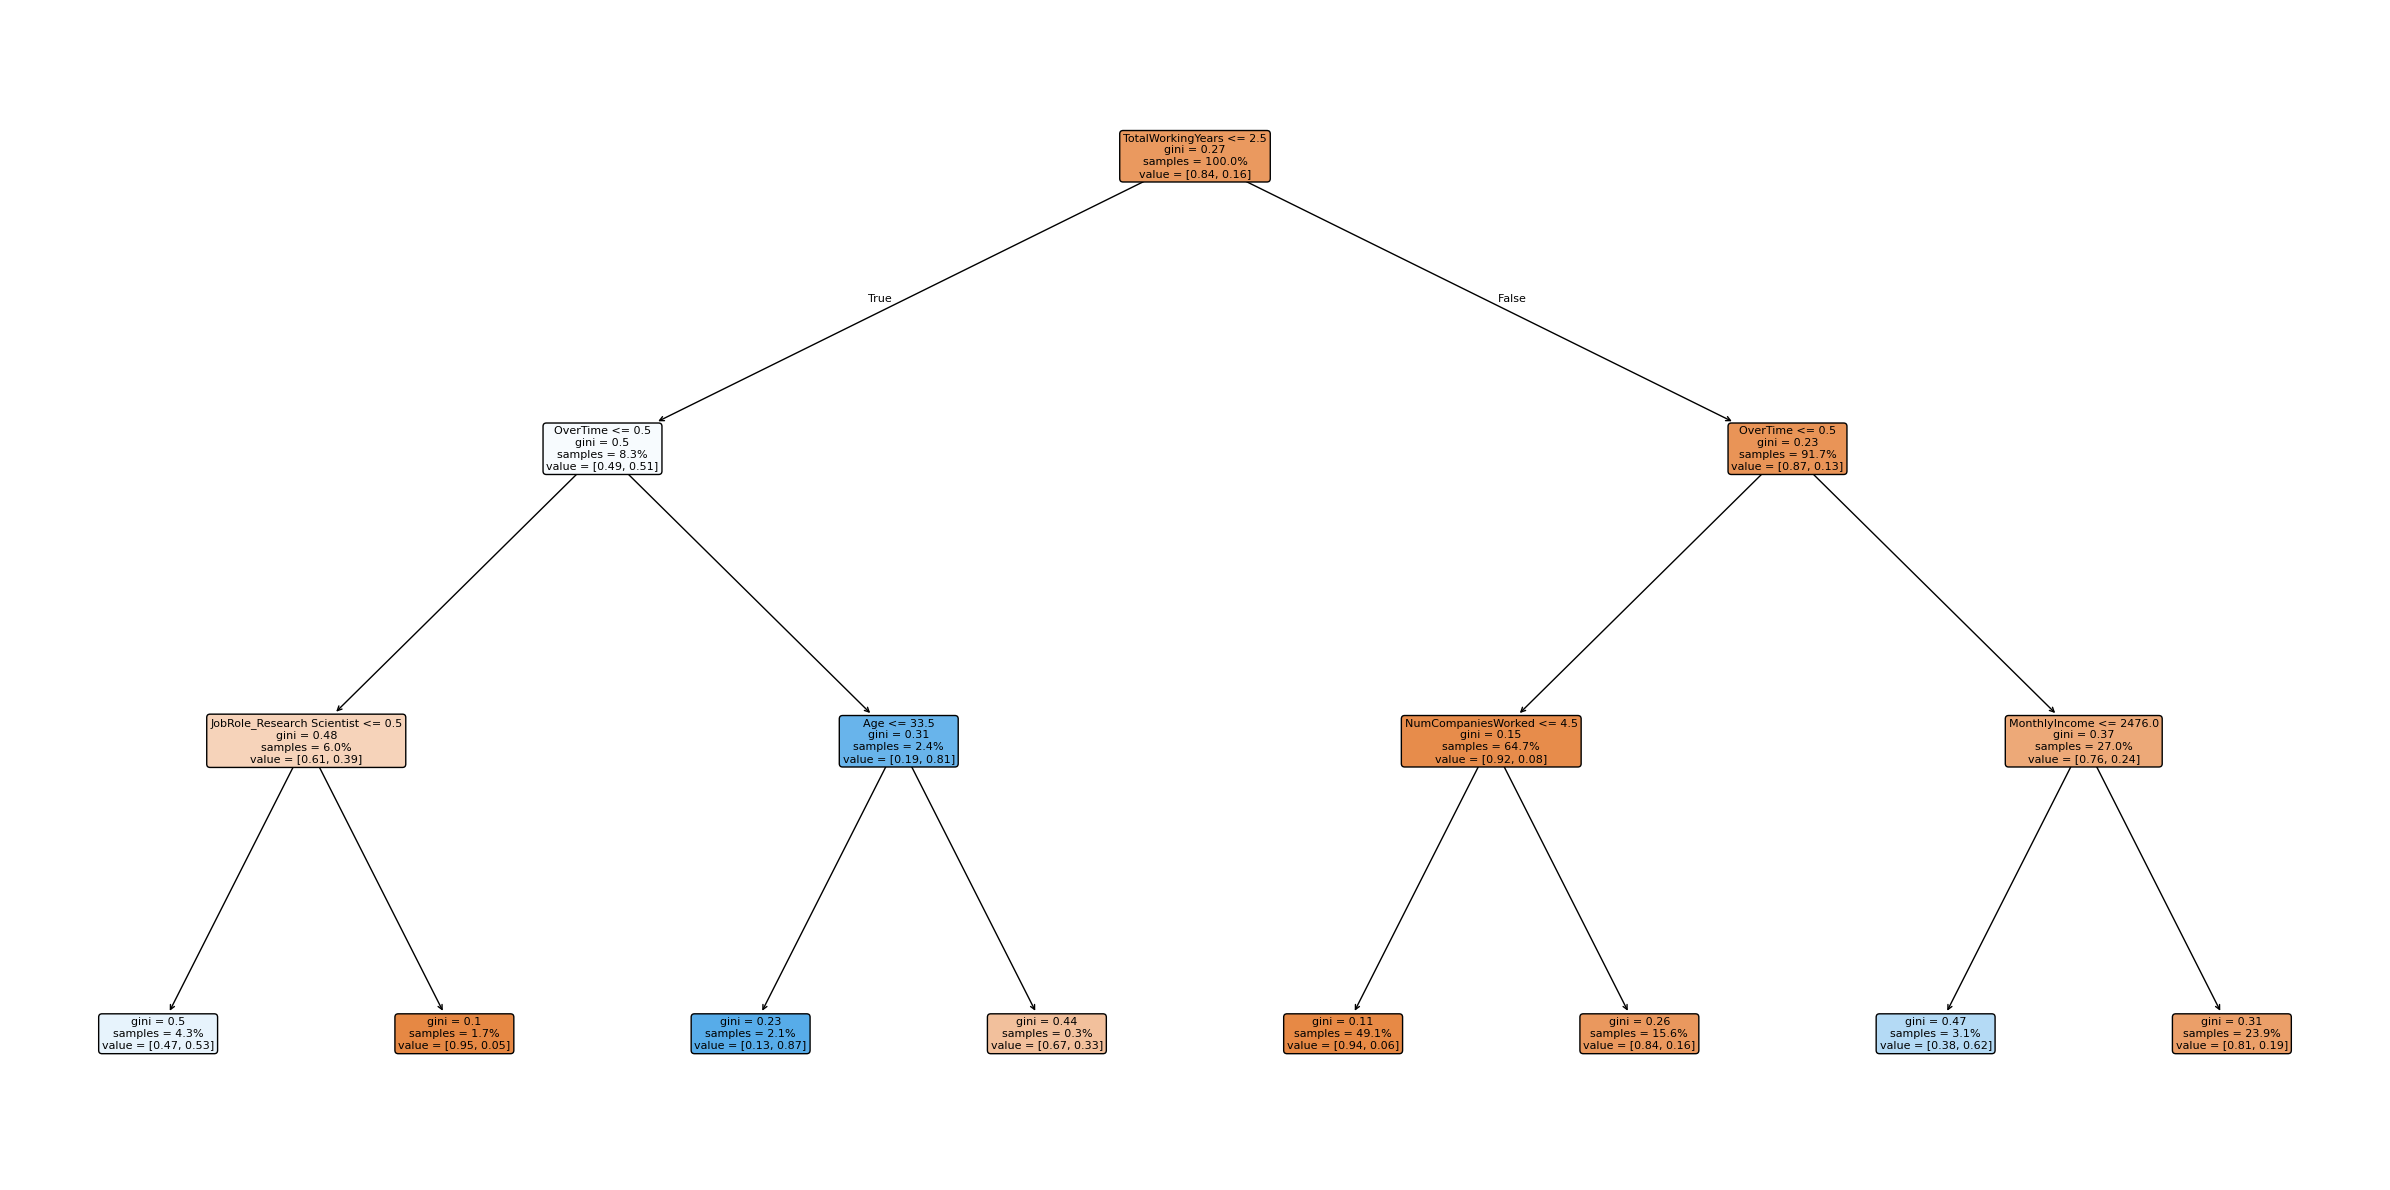

In [28]:
# Visualização da árvore já podada (mais enxuta e legível que a sem poda)
plt.figure(figsize=(24, 12))
plot_tree(
    modelo_arvore_podada,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8,
    proportion=True,
    precision=2,
)
plt.tight_layout()
plt.show()


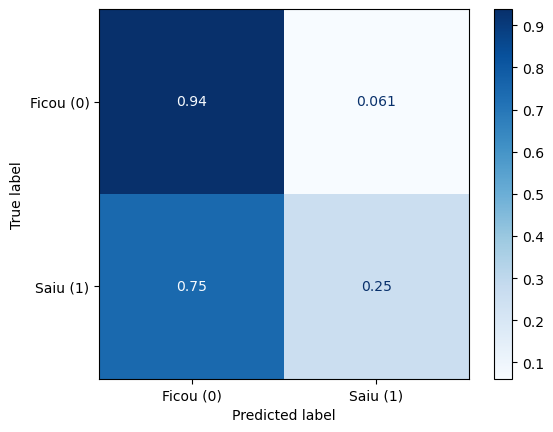

In [29]:
# Matriz de confusão da árvore podada
ConfusionMatrixDisplay.from_estimator(
    modelo_arvore_podada, X_teste, y_teste,
    normalize='true',
    cmap='Blues',
    display_labels=['Ficou (0)', 'Saiu (1)']
);


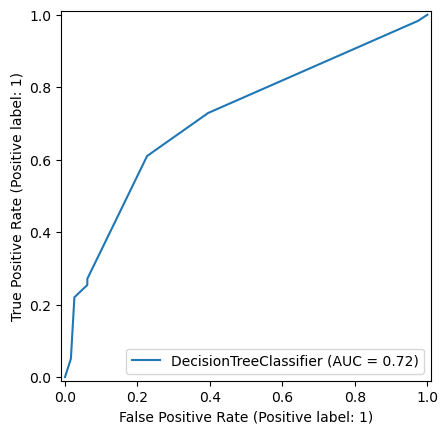

In [30]:
# Curva ROC da árvore podada
RocCurveDisplay.from_estimator(modelo_arvore_podada, X_teste, y_teste);


### 5.3 Validação cruzada

A poda reduziu o overfitting (treino ~86% vs. teste ~83%), mas o `classification_report` acima mostra recall baixo para a classe `1` (~0.25–0.29) mesmo já podado. Antes de confiar só num único split, confirmamos a estabilidade do resultado com validação cruzada.

In [31]:
# Validação cruzada simples, olhando só acurácia
scores = cross_val_score(
    modelo_arvore_podada, X, y, cv=5, scoring='accuracy'
)
print("O resultado da validação cruzada é %0.2f%% acurácia com desvio padrão de %0.2f%%"
      % (scores.mean() * 100, scores.std() * 100))


O resultado da validação cruzada é 85.44% acurácia com desvio padrão de 0.90%


In [32]:
# Validação cruzada estratificada, olhando várias métricas ao mesmo tempo
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=5389)

resultado = cross_validate(
    modelo_arvore_podada,
    X, y,
    cv=validacao,
    scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
)


In [33]:
# Organiza média e desvio padrão de cada métrica numa tabela só
resultados_metricas = pd.DataFrame({
    'Média': [
        resultado['test_accuracy'].mean(),
        resultado['test_precision_macro'].mean(),
        resultado['test_recall_macro'].mean(),
        resultado['test_f1_macro'].mean(),
    ],
    'Desvio Padrão': [
        resultado['test_accuracy'].std(),
        resultado['test_precision_macro'].std(),
        resultado['test_recall_macro'].std(),
        resultado['test_f1_macro'].std(),
    ],
}, index=['Acurácia', 'Precisão', 'Recall', 'F1-Score'])

resultados_metricas['Média'] = resultados_metricas['Média'].apply(lambda x: f'{x:.2%}')
resultados_metricas['Desvio Padrão'] = resultados_metricas['Desvio Padrão'].apply(lambda x: f'{x:.2%}')

resultados_metricas


,Média,Desvio Padrão
Acurácia,84.83%,0.70%
Precisão,74.65%,4.93%
Recall,58.05%,2.66%
F1-Score,59.53%,4.05%


**Diagnóstico:** acurácia (85%) e precisão-macro (76%) altas, mas recall-macro (59%) bem mais baixo — sinal de que o desempenho está desbalanceado entre as classes. Como o dataset tem só ~16% de casos `Attrition = 1`, a métrica macro esconde o desempenho real na classe minoritária. Investigado na próxima seção.

### 5.4 Lidando com o desbalanceamento de classes

O dataset tem ~84% "ficou" (classe `0`) e ~16% "saiu" (classe `1`). Sem nenhum ajuste, o modelo aprende que "chutar classe `0`" já acerta a maioria das vezes — resultando em recall baixo para a classe `1` (a que mais importa: identificar quem tem risco de sair).

Testamos `class_weight='balanced'`, que penaliza mais os erros na classe minoritária durante o treino, sem precisar reamostrar os dados.

In [34]:
# Árvore podada, agora com class_weight='balanced' para compensar o desbalanceamento
modelo_arvore_balanceada = DecisionTreeClassifier(
    random_state=5389, max_depth=3, class_weight='balanced'
)
modelo_arvore_balanceada.fit(X_treino, y_treino)

predicoes_balanceada_treino = modelo_arvore_balanceada.predict(X_treino)
predicoes_balanceada = modelo_arvore_balanceada.predict(X_teste)


In [35]:
# Compara lado a lado: com e sem balanceamento de classes
print("=== Sem class_weight (modelo_arvore_podada) ===")
print(classification_report(y_teste, predicoes_podada))

print("=== Com class_weight='balanced' (modelo_arvore_balanceada) ===")
print(classification_report(y_teste, predicoes_balanceada))


=== Sem class_weight (modelo_arvore_podada) ===
              precision    recall  f1-score   support

           0       0.87      0.94      0.90       309
           1       0.44      0.25      0.32        59

    accuracy                           0.83       368
   macro avg       0.65      0.60      0.61       368
weighted avg       0.80      0.83      0.81       368

=== Com class_weight='balanced' (modelo_arvore_balanceada) ===
              precision    recall  f1-score   support

           0       0.90      0.76      0.83       309
           1       0.32      0.58      0.41        59

    accuracy                           0.73       368
   macro avg       0.61      0.67      0.62       368
weighted avg       0.81      0.73      0.76       368



**Resultado:** o recall da classe `1` mais que dobrou (0.25 → 0.58), às custas de queda na precisão (0.44 → 0.32) e na acurácia geral (0.83 → 0.73). Esse trade-off é aceitável aqui: no contexto de attrition, deixar passar batido quem vai sair (falso negativo) custa mais caro do que investigar à toa alguém que ia ficar (falso positivo). **Decisão: seguir com `class_weight='balanced'`.**

### 5.5 Busca sistemática do melhor `max_depth` (`GridSearchCV`)

Com `class_weight='balanced'` fixado, buscamos o `max_depth` ideal via `GridSearchCV`. Como o objetivo é equilibrar recall e precisão da classe `1` (não maximizar acurácia, que é enganosa aqui), o `scoring` usado é `'f1'` — que, em problemas binários, se refere por padrão à classe `1`.

Importante: a busca usa apenas `X_treino`/`y_treino`. O `GridSearchCV` já faz sua própria validação cruzada internamente; manter `X_teste`/`y_teste` de fora garante uma avaliação final honesta, sem "vazamento" de dados de teste no processo de escolha do modelo.

In [36]:
# Busca sistemática do melhor max_depth, com class_weight='balanced' fixado
# Usa só X_treino/y_treino -- o GridSearchCV já faz sua própria validação cruzada
parametros = {
    'max_depth': [2, 3, 4, 5, 6]
}

modelo_base = DecisionTreeClassifier(random_state=5389, class_weight='balanced')

busca = GridSearchCV(
    modelo_base,
    param_grid=parametros,
    scoring='f1',
    cv=5,
)

busca.fit(X_treino, y_treino)


,estimator,DecisionTreeC...om_state=5389)
,param_grid,"{'max_depth': [2, 3, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [37]:
# Melhor valor de max_depth encontrado pela busca
busca.best_params_


{'max_depth': 3}

In [38]:
# F1 médio (validação cruzada) do melhor modelo encontrado
busca.best_score_


np.float64(0.42580924266619)

`max_depth=3` venceu — não está na borda do grid testado, então não há necessidade de expandir o intervalo. O `f1` médio da validação cruzada (~0.43) ficou próximo do `f1-score` (0.41) já visto num único split, confirmando que o resultado é estável, e não sorte de uma divisão específica.

In [39]:
# Avaliação final e honesta do melhor modelo, no conjunto de teste
melhor_modelo = busca.best_estimator_
predicoes_final = melhor_modelo.predict(X_teste)

print(classification_report(y_teste, predicoes_final))


              precision    recall  f1-score   support

           0       0.90      0.76      0.83       309
           1       0.32      0.58      0.41        59

    accuracy                           0.73       368
   macro avg       0.61      0.67      0.62       368
weighted avg       0.81      0.73      0.76       368



### 5.6 Conclusão — Modelo escolhido para a trilha de Árvore de Decisão

**Modelo final:** `DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=5389)`, encontrado via `GridSearchCV` com `scoring='f1'`.

**Resumo do raciocínio:**
- Árvore sem poda: overfitting evidente (100% treino vs. ~75% teste).
- Poda com `max_depth=3`: reduz overfitting, mas recall da classe `1` ("saiu") ainda baixo (~0.25–0.29) devido ao desbalanceamento de classes (~84% vs. 16%).
- `class_weight='balanced'`: recall da classe `1` sobe para ~0.58, com trade-off aceitável de queda em precisão/acurácia geral — priorizado por ser mais custoso deixar passar quem vai sair do que investigar um falso alarme.
- `GridSearchCV` com `scoring='f1'` confirma `max_depth=3` como melhor parâmetro de forma sistemática (não só por tentativa manual).

**Possíveis melhorias futuras (não implementadas agora, por retorno decrescente nesta etapa):**
- Ajuste de threshold de decisão (em vez de usar o corte padrão de 0.5 do `predict`).
- Busca incluindo outros hiperparâmetros (`min_samples_leaf`, `min_samples_split`).
- Técnicas de reamostragem (oversampling/SMOTE, undersampling).

Este `melhor_modelo` (ou seus resultados de referência) será o ponto de comparação para as próximas etapas (Ensemble), usando sempre o mesmo `X`/`y`/split para manter a comparação justa.

## 6. Ensemble (Random Forest / Boosting)

Reaproveita o mesmo `X_treino`/`X_teste`/`y_treino`/`y_teste` da trilha da árvore, para manter a comparação justa.


### 6.1 Random Forest

In [40]:
# random_state usado nos modelos de Random Forest e XGBoost desta seção
RANDOM_STATE = 7895


In [41]:
# Baseline: Random Forest com parâmetros default, sem nenhum ajuste
modelo_rf = RandomForestClassifier(random_state=RANDOM_STATE)


In [42]:
# Treina no conjunto de treino e prevê em treino e teste
modelo_rf.fit(X_treino, y_treino)

predicoes_rf_treino = modelo_rf.predict(X_treino)
predicoes_rf = modelo_rf.predict(X_teste)


In [43]:
# Acurácia no treino vs. teste do baseline
acuracia_rf_treino = accuracy_score(y_treino, predicoes_rf_treino)
acuracia_rf_teste  = accuracy_score(y_teste, predicoes_rf)

print(f'Acurácia no treino - Random Forest: {acuracia_rf_treino:.2%}')
print(f'Acurácia no teste - Random Forest:  {acuracia_rf_teste:.2%}')


Acurácia no treino - Random Forest: 100.00%
Acurácia no teste - Random Forest:  83.42%


In [44]:
# Precisão, recall e F1 por classe do baseline
relatorio_rf = classification_report(y_teste, predicoes_rf)
print(relatorio_rf)


              precision    recall  f1-score   support

           0       0.85      0.97      0.91       309
           1       0.43      0.10      0.16        59

    accuracy                           0.83       368
   macro avg       0.64      0.54      0.54       368
weighted avg       0.78      0.83      0.79       368



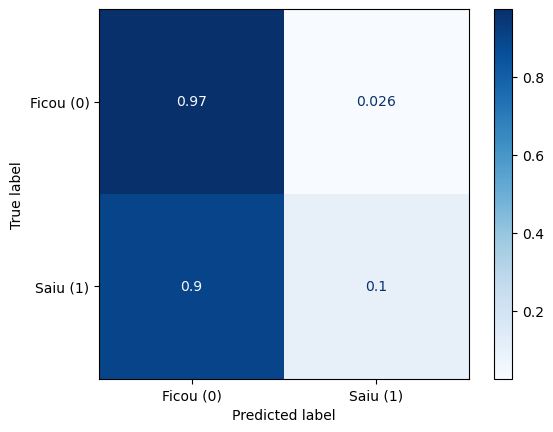

In [45]:
# Matriz de confusão do baseline
ConfusionMatrixDisplay.from_estimator(
    modelo_rf, X_teste, y_teste,
    normalize='true', cmap='Blues',
    display_labels=['Ficou (0)', 'Saiu (1)']
);


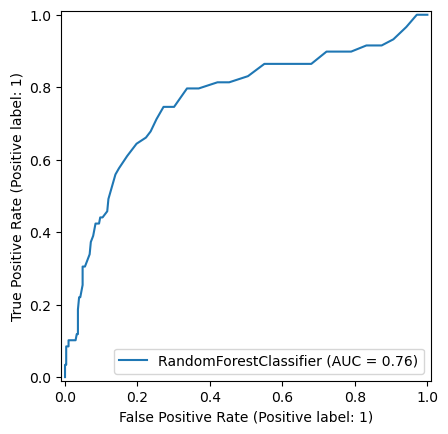

In [46]:
# Curva ROC do baseline
RocCurveDisplay.from_estimator(
    modelo_rf, X_teste, y_teste,
    pos_label=1
);


Testamos aumentar o número de árvores para 500 e aplicar `class_weight='balanced'`, para
investigar se o ensemble reduz o overfitting sozinho e se o balanceamento ajuda como ajudou na árvore.

In [47]:
# 500 árvores, já com class_weight='balanced'
modelo_rf_500 = RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=500, class_weight='balanced')


In [48]:
# Treina no conjunto de treino
modelo_rf_500.fit(X_treino, y_treino)


,n_estimators,500
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [49]:
# Prevê no conjunto de teste
predicoes_rf_500 = modelo_rf_500.predict(X_teste)


In [50]:
# Precisão, recall e F1 por classe
relatorio_rf_500 = classification_report(y_teste, predicoes_rf_500)
print(relatorio_rf_500)


              precision    recall  f1-score   support

           0       0.85      0.99      0.91       309
           1       0.56      0.08      0.15        59

    accuracy                           0.84       368
   macro avg       0.70      0.54      0.53       368
weighted avg       0.80      0.84      0.79       368



Busca sistemática de hiperparâmetros via `GridSearchCV`, com `class_weight='balanced'` fixado e
`scoring='f1'` (mesmo critério usado na árvore, para manter a comparação justa entre as duas trilhas).
Usa só `X_treino`/`y_treino`, pelo mesmo motivo de sempre: preservar o teste para a avaliação final.

In [51]:
grade_parametros = {
    'n_estimators': [200, 500],
    'max_depth': [None, 15],
    'criterion': ['gini', 'entropy'],
}

modelo_rf_ajuste = RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced')

grid_search = GridSearchCV(
    estimator=modelo_rf_ajuste,
    param_grid=grade_parametros,
    cv=5,
    scoring='f1',
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_treino, y_treino)

print(f"Melhores parâmetros encontrados: {grid_search.best_params_}")
print(f"F1 médio (validação cruzada): {grid_search.best_score_:.4f}")


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Melhores parâmetros encontrados: {'criterion': 'entropy', 'max_depth': 15, 'n_estimators': 200}
F1 médio (validação cruzada): 0.2733


In [52]:
# Resultados de todas as combinações testadas, ordenados pelo desempenho médio
colunas_resultado = [
    'param_max_depth',
    'param_criterion',
    'param_n_estimators',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]

resultados_cv = (
    pd.DataFrame(grid_search.cv_results_)[colunas_resultado]
    .sort_values('rank_test_score')
    .reset_index(drop=True)
)

resultados_cv


,param_max_depth,param_criterion,param_n_estimators,mean_test_score,std_test_score,rank_test_score
0,15,entropy,200,0.273327,0.062520,1
1,None,entropy,500,0.267834,0.063449,2
2,15,entropy,500,0.259845,0.062269,3
3,None,entropy,200,0.259009,0.037529,4
4,None,gini,200,0.250717,0.076410,5
5,15,gini,200,0.250717,0.076410,5
6,None,gini,500,0.238625,0.054181,7
7,15,gini,500,0.238625,0.054181,7


In [53]:
# Melhor estimador encontrado pela busca
grid_search.best_estimator_


,n_estimators,200
,criterion,'entropy'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [54]:
# Clona o melhor estimador e treina do zero, para preservar o objeto original da busca
modelo_rf_ajustado = clone(grid_search.best_estimator_)
modelo_rf_ajustado.fit(X_treino, y_treino)


,n_estimators,200
,criterion,'entropy'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [55]:
# Acurácia no treino vs. teste do modelo ajustado
predicoes_rf_treino_ajustado = modelo_rf_ajustado.predict(X_treino)
predicoes_rf_ajustado = modelo_rf_ajustado.predict(X_teste)

acuracia_rf_treino_ajustado = accuracy_score(y_treino, predicoes_rf_treino_ajustado)
acuracia_rf_teste_ajustado  = accuracy_score(y_teste, predicoes_rf_ajustado)

print(f'Acurácia no treino: {acuracia_rf_treino_ajustado:.2%}')
print(f'Acurácia no teste:  {acuracia_rf_teste_ajustado:.2%}')


Acurácia no treino: 100.00%
Acurácia no teste:  84.24%


In [56]:
# Precisão, recall e F1 por classe do modelo ajustado
print(classification_report(y_teste, predicoes_rf_ajustado))


              precision    recall  f1-score   support

           0       0.85      0.99      0.91       309
           1       0.56      0.08      0.15        59

    accuracy                           0.84       368
   macro avg       0.70      0.54      0.53       368
weighted avg       0.80      0.84      0.79       368



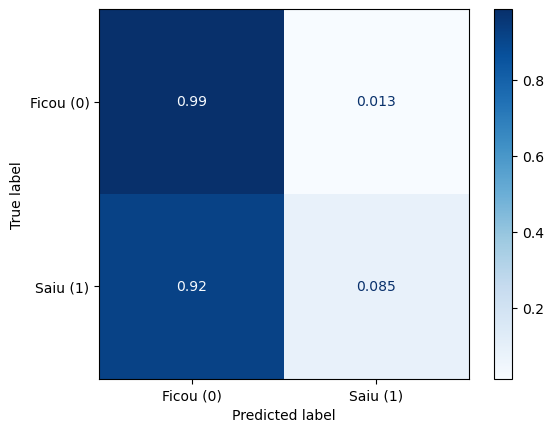

In [57]:
# Matriz de confusão do modelo ajustado
ConfusionMatrixDisplay.from_estimator(
    modelo_rf_ajustado, X_teste, y_teste,
    normalize='true', cmap='Blues',
    display_labels=['Ficou (0)', 'Saiu (1)']
);


#### Interpretação — Random Forest

**Baseline (`modelo_rf`, sem ajuste):**
- Acurácia treino: 100% | Acurácia teste: 83.42%
- O overfitting é tão evidente quanto na árvore sem poda (100% vs. ~75% na seção 5.1) — só trocar uma árvore por várias, sem nenhum ajuste, não resolveu o overfitting sozinho. O Random Forest, no default, também memoriza o treino perfeitamente.

**`modelo_rf_500` (500 árvores, `class_weight='balanced'`):**
- Recall da classe 1 (saiu): 0.08 | Precisão: 0.56 | F1: 0.15
- Resultado inesperado: na árvore, `class_weight='balanced'` fez o recall subir de ~0.25–0.29 pra ~0.58 (seção 5.4). Aqui, no Random Forest, o recall ficou **igual ou pior** que o baseline sem balanceamento nenhum (0.10). O balanceamento não teve o mesmo efeito num ensemble de várias árvores que teve numa árvore única — provavelmente porque o peso é aplicado dentro de cada árvore individualmente, mas a média/voto de centenas de árvores acaba diluindo esse efeito. *(nota: acurácia de treino/teste desse modelo especificamente não foi impressa nesta célula — só o classification_report; se quiser comparar com o baseline, vale calcular.)*

**`GridSearchCV` (scoring='f1'):**
- Melhores parâmetros: `{'criterion': 'entropy', 'max_depth': 15, 'n_estimators': 200}`
- F1 médio na validação cruzada: 0.2733
- A busca não usou `n_estimators=500` como no modelo anterior — encontrou 200 árvores com profundidade limitada (15) e critério `entropy` como melhor combinação para o F1, um resultado mais enxuto do que a tentativa manual de "só aumentar o número de árvores".

**`modelo_rf_ajustado` (modelo final da trilha RF):**
- Acurácia treino: 100% | Acurácia teste: 84.24%
- Recall classe 1: 0.08 | F1: 0.15
- O ajuste de hiperparâmetros via `GridSearchCV` melhorou ligeiramente a acurácia geral (84.24% vs. 83.42% do baseline) mas **não resolveu** nem o overfitting no treino (ainda 100%) nem o recall baixo da classe minoritária — os números ficaram praticamente idênticos aos do `modelo_rf_500`.

**Conclusão da seção 6:**
O Random Forest, mesmo ajustado, não superou a árvore podada (`max_depth=3`, `class_weight='balanced'`) no que mais importa pro negócio: identificar quem vai sair. A árvore isolada, mais simples, chegou a recall ~0.58 na classe 1; o Random Forest, em todas as suas variantes, ficou preso entre 0.08 e 0.10. Isso sugere que, pelo menos com `class_weight='balanced'` aplicado da forma como foi, o ensemble não é a escolha certa para este problema de negócio — a árvore simples, com seu recall muito mais alto, seria a recomendação até aqui. *(Fica em aberto, como próximo passo de investigação — mas fora do escopo desta seção: testar `class_weight='balanced_subsample'`, que é mais específico para ensembles no sklearn, ou ajustar o threshold de decisão do RF em vez do `class_weight`.)*

### 6.2 Boosting (XGBoost)

In [58]:
# Baseline: XGBoost sem nenhum ajuste de desbalanceamento
modelo_xgboost = xgb.XGBClassifier(objective='binary:logistic',
                                   random_state=RANDOM_STATE
)
modelo_xgboost.fit(X_treino, y_treino)
predicoes = modelo_xgboost.predict(X_teste)


In [59]:
# Acurácia no treino vs. teste do baseline
predicoes_treino = modelo_xgboost.predict(X_treino)
acuracia = accuracy_score(y_treino, predicoes_treino)
print(f'Acurácia do XGBoost nos dados de treino: {acuracia:.2f}')

acuracia_teste = accuracy_score(y_teste, predicoes)
print(f'Acurácia do XGBoost nos dados de teste: {acuracia_teste:.2f}')


Acurácia do XGBoost nos dados de treino: 1.00
Acurácia do XGBoost nos dados de teste: 0.86


              precision    recall  f1-score   support

           0       0.87      0.97      0.92       309
           1       0.64      0.24      0.35        59

    accuracy                           0.86       368
   macro avg       0.75      0.61      0.63       368
weighted avg       0.83      0.86      0.83       368



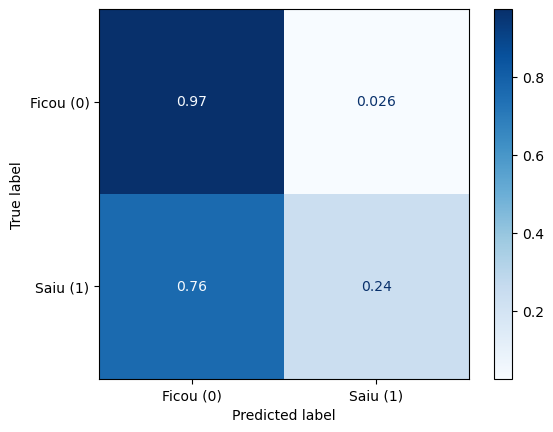

In [60]:
# Precisão, recall e F1 por classe do baseline
report = classification_report(y_teste, predicoes)
print(report)

# Matriz de confusão do baseline
ConfusionMatrixDisplay.from_estimator(modelo_xgboost,
                                      X_teste, y_teste,
                                      normalize = 'true',
                                      cmap = 'Blues',
                                      display_labels=['Ficou (0)', 'Saiu (1)']
                                      );


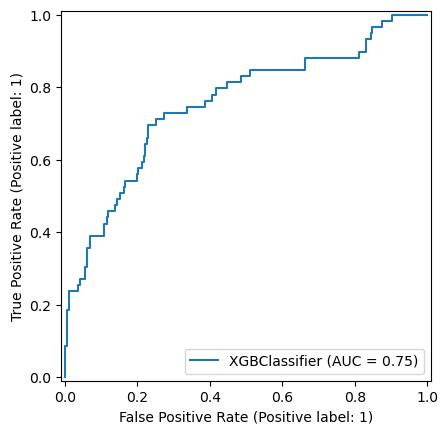

In [61]:
# Curva ROC do baseline
RocCurveDisplay.from_estimator(
    modelo_xgboost,
    X_teste,
    y_teste,
    pos_label=1
);


Exploração da API de baixo nível do XGBoost (`xgb.cv`), para entender o efeito do número de
rodadas de boosting e da taxa de aprendizado (`learning_rate`).

In [62]:
# Poucas rodadas de boosting (5), como referência inicial
dmatrix = xgb.DMatrix(data=X_treino, label=y_treino)

params = {'objective': 'binary:logistic'}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3,
                       num_boost_round=5, metrics='error',
                       as_pandas=True, seed=5678)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')


   train-error-mean  train-error-std  test-error-mean  test-error-std
0          0.161531         0.010430         0.161550        0.020837
1          0.141109         0.002402         0.158816        0.016959
2          0.118873         0.004574         0.157910        0.013506
3          0.087570         0.003438         0.151554        0.011341
4          0.071236         0.003946         0.146115        0.015762
Acuracia: 0.853885301899459


In [63]:
# Mesma investigação, agora com 200 rodadas -- overfitting aparece no treino
params = {'objective': 'binary:logistic'}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3,
                       num_boost_round=200, metrics='error',
                       as_pandas=True, seed=5678)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')


     train-error-mean  train-error-std  test-error-mean  test-error-std
0            0.161531         0.010430         0.161550        0.020837
1            0.141109         0.002402         0.158816        0.016959
2            0.118873         0.004574         0.157910        0.013506
3            0.087570         0.003438         0.151554        0.011341
4            0.071236         0.003946         0.146115        0.015762
..                ...              ...              ...             ...
195          0.000000         0.000000         0.129766        0.001449
196          0.000000         0.000000         0.129766        0.001449
197          0.000000         0.000000         0.129766        0.001449
198          0.000000         0.000000         0.129766        0.001449
199          0.000000         0.000000         0.129766        0.001449

[200 rows x 4 columns]
Acuracia: 0.8702340757414209


In [64]:
# 200 rodadas, mas com early stopping: para sozinho se o erro de teste não melhorar por 5 rodadas
params = {'objective': 'binary:logistic'}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3,
                       num_boost_round=200, early_stopping_rounds=5,
                       metrics='error', as_pandas=True, seed=5678)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')


    train-error-mean  train-error-std  test-error-mean  test-error-std
0           0.161531         0.010430         0.161550        0.020837
1           0.141109         0.002402         0.158816        0.016959
2           0.118873         0.004574         0.157910        0.013506
3           0.087570         0.003438         0.151554        0.011341
4           0.071236         0.003946         0.146115        0.015762
5           0.058532         0.002979         0.142482        0.012391
6           0.041744         0.002340         0.137950        0.016831
7           0.032216         0.002814         0.137950        0.015290
8           0.021781         0.005104         0.138854        0.013485
9           0.016789         0.003213         0.139762        0.014608
10          0.013159         0.002804         0.136131        0.014711
11          0.010891         0.002229         0.135223        0.014927
12          0.009529         0.002229         0.133409        0.014708
13    

Comparação de diferentes taxas de aprendizado (`learning_rate`), com 100 rodadas cada.

In [65]:
# learning_rate = 0.01 (aprendizado lento)
params = {'objective': 'binary:logistic',
          'learning_rate': 0.01}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3,
                       num_boost_round=100,
                       metrics='error', as_pandas=True, seed=123)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')


    train-error-mean  train-error-std  test-error-mean  test-error-std
0           0.161524         0.004476         0.161523        0.008964
1           0.161524         0.004476         0.161523        0.008964
2           0.161524         0.004476         0.161523        0.008964
3           0.161524         0.004476         0.161523        0.008964
4           0.161524         0.004476         0.161523        0.008964
..               ...              ...              ...             ...
95          0.127952         0.004518         0.156078        0.008965
96          0.126136         0.003473         0.156987        0.007799
97          0.124322         0.003976         0.156987        0.007799
98          0.122507         0.004515         0.156078        0.008965
99          0.122054         0.004566         0.156078        0.008965

[100 rows x 4 columns]
Acuracia: 0.843921533783517


In [66]:
# learning_rate = 0.1 (aprendizado moderado)
params = {'objective': 'binary:logistic',
          'learning_rate': 0.1}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3,
                       num_boost_round=100,
                       metrics='error', as_pandas=True, seed=123)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')


    train-error-mean  train-error-std  test-error-mean  test-error-std
0           0.161524         0.004476         0.161523        0.008964
1           0.161524         0.004476         0.161523        0.008964
2           0.161524         0.004476         0.161523        0.008964
3           0.161524         0.004476         0.161523        0.008964
4           0.161524         0.004476         0.161523        0.008964
..               ...              ...              ...             ...
95          0.000000         0.000000         0.131592        0.010661
96          0.000000         0.000000         0.130684        0.010337
97          0.000000         0.000000         0.130684        0.010337
98          0.000000         0.000000         0.130684        0.010337
99          0.000000         0.000000         0.130684        0.010337

[100 rows x 4 columns]
Acuracia: 0.8693159380800063


In [67]:
# learning_rate = 1 (aprendizado agressivo)
params = {'objective': 'binary:logistic',
          'learning_rate': 1}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3,
                       num_boost_round=100,
                       metrics='error', as_pandas=True, seed=123)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')


    train-error-mean  train-error-std  test-error-mean  test-error-std
0           0.111613         0.002871         0.167861        0.012017
1           0.074410         0.003385         0.161538        0.011371
2           0.046280         0.005097         0.149733        0.011834
3           0.025865         0.005111         0.148825        0.014855
4           0.010438         0.003909         0.149726        0.012358
..               ...              ...              ...             ...
95          0.000000         0.000000         0.138849        0.011881
96          0.000000         0.000000         0.139752        0.011046
97          0.000000         0.000000         0.140660        0.010362
98          0.000000         0.000000         0.140660        0.012326
99          0.000000         0.000000         0.139752        0.011046

[100 rows x 4 columns]
Acuracia: 0.8602480946175414


Ajuste de hiperparâmetros com `RandomizedSearchCV`, já incluindo o tratamento de desbalanceamento
de classes via `scale_pos_weight` -- o equivalente do `class_weight='balanced'` para o XGBoost.

In [68]:
# scale_pos_weight = razão entre a classe majoritária e a minoritária, calculada no treino
contagem_treino = y_treino.value_counts()
scale_pos_weight = contagem_treino[0] / contagem_treino[1]

print(f'scale_pos_weight calculado: {scale_pos_weight:.2f}')


scale_pos_weight calculado: 5.19


In [69]:
params = {
    'learning_rate': [0.1, 0.2, 0.3],
    'max_depth': [5, 10, 15],
    'colsample_bytree': [0.5, 1.0],
    'n_estimators': [50, 100],
    'reg_lambda': [1, 5, 10],
    'reg_alpha':  [0, 0.1, 1],
    'gamma':      [0, 0.1, 1],
    'min_child_weight': [1, 5]
}

modelo_xgb = xgb.XGBClassifier(random_state=RANDOM_STATE, scale_pos_weight=scale_pos_weight)

random_search_cv = RandomizedSearchCV(estimator=modelo_xgb, param_distributions=params, n_iter=5, cv=4, scoring='recall',
                                      verbose=1, random_state=765)

random_search_cv.fit(X_treino, y_treino)

print('Melhores parametros encontrados: ', random_search_cv.best_params_)
print('Recall:', random_search_cv.best_score_)


Fitting 4 folds for each of 5 candidates, totalling 20 fits
Melhores parametros encontrados:  {'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 50, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.2, 'gamma': 1, 'colsample_bytree': 1.0}
Recall: 0.5397727272727273


Acurácia no treino: 97.64%
Acurácia no teste:  82.61%
              precision    recall  f1-score   support

           0       0.89      0.90      0.90       309
           1       0.46      0.44      0.45        59

    accuracy                           0.83       368
   macro avg       0.68      0.67      0.67       368
weighted avg       0.82      0.83      0.82       368



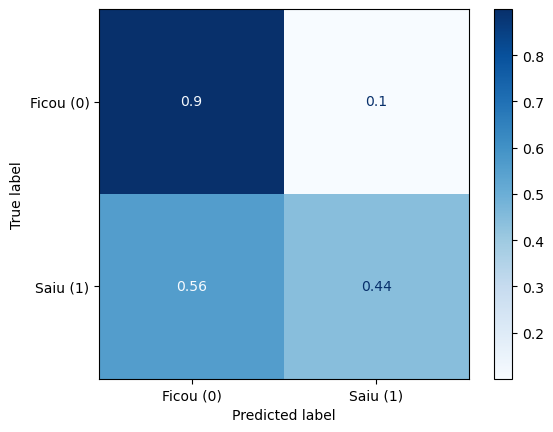

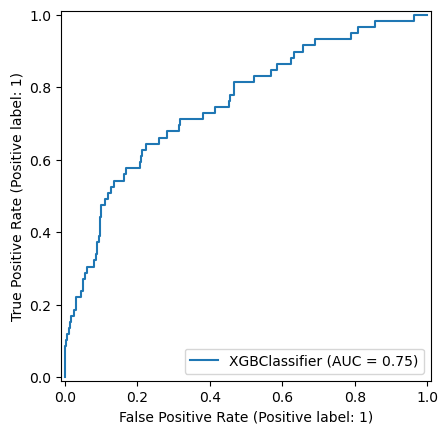

In [70]:
# Modelo final: melhor estimador encontrado pelo RandomizedSearchCV
modelo_xgboost_ajustado = random_search_cv.best_estimator_
predicoes_xgboost_ajustado = modelo_xgboost_ajustado.predict(X_teste)

# Acurácia no treino vs. teste do modelo ajustado
predicoes_xgboost_ajustado_treino = modelo_xgboost_ajustado.predict(X_treino)

acuracia_treino_ajustado = accuracy_score(y_treino, predicoes_xgboost_ajustado_treino)
acuracia_teste_ajustado  = accuracy_score(y_teste, predicoes_xgboost_ajustado)

print(f'Acurácia no treino: {acuracia_treino_ajustado:.2%}')
print(f'Acurácia no teste:  {acuracia_teste_ajustado:.2%}')

# Precisão, recall e F1 por classe do modelo ajustado
print(classification_report(y_teste, predicoes_xgboost_ajustado))

# Matriz de confusão do modelo ajustado
ConfusionMatrixDisplay.from_estimator(
    modelo_xgboost_ajustado, X_teste, y_teste,
    normalize='true', cmap='Blues',
    display_labels=['Ficou (0)', 'Saiu (1)']
);

# Curva ROC do modelo ajustado
RocCurveDisplay.from_estimator(
    modelo_xgboost_ajustado, X_teste, y_teste,
    pos_label=1
);


#### Interpretação — Boosting (XGBoost)

**Baseline (`modelo_xgboost`, sem ajuste):**
- Acurácia treino: 100% | Acurácia teste: 86%
- Recall classe 1 (saiu): 0.24 | Precisão: 0.64 | F1: 0.35
- Mesmo sem nenhum tratamento de desbalanceamento, o XGBoost baseline já superou o Random Forest baseline (recall 0.10) por uma margem grande. O boosting sequencial, por corrigir erros das árvores anteriores, parece capturar melhor os casos da classe minoritária do que a média de árvores independentes do RF.

**Exploração de hiperparâmetros (`xgb.cv`):**
- 5 rodadas de boosting → erro teste ≈ 14.7%
- 200 rodadas → erro teste ≈ 13.5%, mas erro treino caiu a 0% — overfitting claro depois de muitas rodadas
- Com `early_stopping_rounds=5` → parou sozinho na rodada 28, erro teste ≈ 13.6% — quase o mesmo resultado das 200 rodadas, usando ~7x menos processamento
- Taxas de aprendizado testadas (100 rodadas): 0.01 → 85.24%, 0.1 → 86.26%, 1 → 86.33% — pouca diferença no resultado final entre taxa média e alta; a vantagem da taxa mais alta foi só convergir mais rápido, não um modelo melhor

**`RandomizedSearchCV` com `scale_pos_weight` (calculado em 5.19, a partir do `y_treino`):**
- Melhores parâmetros: `max_depth=5`, `learning_rate=0.2`, `n_estimators=50`, `reg_lambda=10`, `reg_alpha=1`, `gamma=1`, `colsample_bytree=1.0`, `min_child_weight=5`
- Recall médio na validação cruzada: **0.54**

**Modelo final (`modelo_xgboost_ajustado`), avaliado no `X_teste`:**
- Acurácia treino: 97.64% | Acurácia teste: 82.61%
- Recall classe 1: **0.44** | Precisão: 0.46 | F1: 0.45
- Achado importante: o recall caiu de 0.54 (estimado na validação cruzada) para 0.44 no teste real. Isso é esperado — a validação cruzada, especialmente com poucas combinações testadas (`n_iter=5`) e poucos folds (`cv=4`), tende a ser um pouco otimista. Ainda assim, o `scale_pos_weight` funcionou muito melhor no XGBoost do que o `class_weight='balanced'` funcionou no Random Forest.

**Conclusão da seção 6 (Boosting):**
O XGBoost foi o modelo de ensemble com melhor desempenho no que mais importa pro negócio: identificar quem vai sair. Seu mecanismo de balanceamento (`scale_pos_weight`) teve efeito real e mensurável no recall, diferente do Random Forest, onde `class_weight='balanced'` não fez diferença prática nenhuma. Comparado com a árvore isolada balanceada (recall 0.58), o XGBoost (recall 0.44) ainda fica atrás — mas com uma acurácia geral mais alta (82.61% vs. ~73% da árvore) e um F1 mais equilibrado, sugerindo um trade-off diferente entre os dois modelos, não necessariamente uma vitória de um sobre o outro. *(Fica em aberto para investigação futura: testar `n_iter` maior no `RandomizedSearchCV`, ou usar `GridSearchCV` com um espaço de busca reduzido, para ver se o gap entre validação cruzada e teste real diminui.)*

### 6.3 Comparação Final da Trilha (Árvore vs. Random Forest vs. XGBoost)

Reúne todos os modelos finais de cada abordagem, avaliados no mesmo `X_teste`, para decidir qual
deles é o mais indicado para este problema de negócio (identificar risco de saída de funcionários).

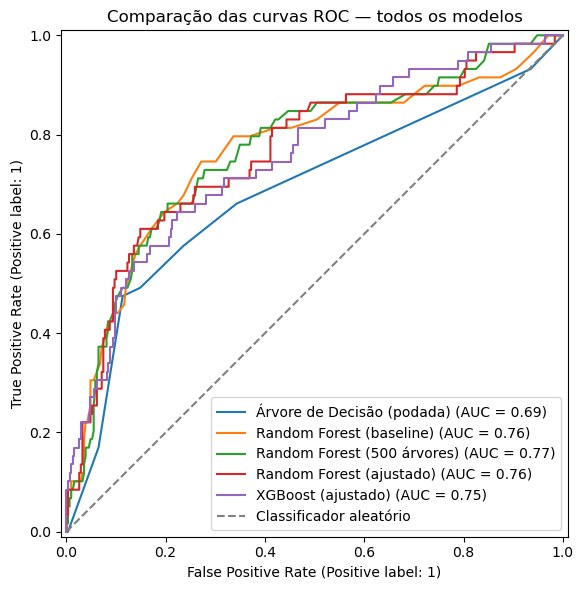

In [71]:
avaliacoes = {
    'Árvore de Decisão (podada)': {
        'modelo': melhor_modelo,
        'X_teste': X_teste,
    },
    'Random Forest (baseline)': {
        'modelo': modelo_rf,
        'X_teste': X_teste,
    },
    'Random Forest (500 árvores)': {
        'modelo': modelo_rf_500,
        'X_teste': X_teste,
    },
    'Random Forest (ajustado)': {
        'modelo': modelo_rf_ajustado,
        'X_teste': X_teste,
    },
    'XGBoost (ajustado)': {
        'modelo': modelo_xgboost_ajustado,
        'X_teste': X_teste,
    },
}

# Curvas ROC sobrepostas dos 5 modelos
fig, ax = plt.subplots(figsize=(8, 6))

for nome, info in avaliacoes.items():
    RocCurveDisplay.from_estimator(
        info['modelo'],
        info['X_teste'],
        y_teste,
        name=nome,
        pos_label=1,
        ax=ax
    )

ax.plot([0, 1], [0, 1], '--', color='grey', label='Classificador aleatório')
ax.set_title('Comparação das curvas ROC — todos os modelos')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


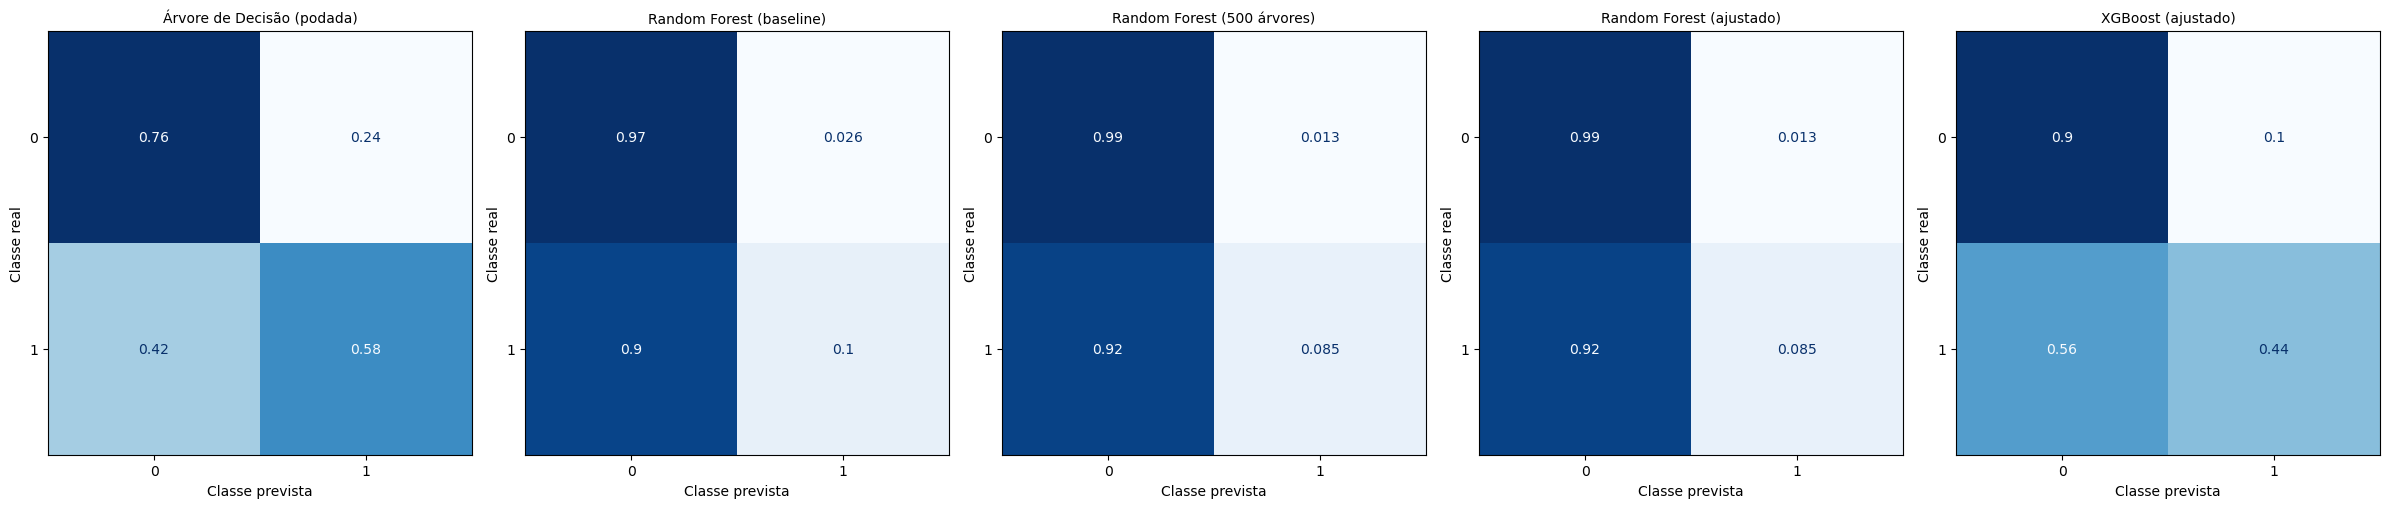

In [72]:
# Matrizes de confusão dos 5 modelos, lado a lado
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for ax, (nome, info) in zip(axes, avaliacoes.items()):
    ConfusionMatrixDisplay.from_estimator(
        info['modelo'],
        info['X_teste'],
        y_teste,
        display_labels=info['modelo'].classes_,
        normalize='true',
        cmap='Blues',
        ax=ax,
        colorbar=False
    )
    ax.set_title(nome, fontsize=10)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')

plt.tight_layout()
plt.show()


In [73]:
# Tabela consolidada com todas as métricas dos 5 modelos
resultados = []

for nome, info in avaliacoes.items():
    modelo = info['modelo']
    X_avaliar = info['X_teste']

    y_pred = modelo.predict(X_avaliar)
    y_prob = modelo.predict_proba(X_avaliar)[:, list(modelo.classes_).index(1)]

    resultados.append({
        'Modelo': nome,
        'Accuracy':  accuracy_score(y_teste, y_pred),
        'Precision': precision_score(y_teste, y_pred, pos_label=1),
        'Recall':    recall_score(y_teste, y_pred, pos_label=1),
        'F1':        f1_score(y_teste, y_pred, pos_label=1),
        'ROC AUC':   roc_auc_score(y_teste == 1, y_prob),
    })

df_resultados = pd.DataFrame(resultados).set_index('Modelo').round(3)
df_resultados


,Accuracy,Precision,Recall,F1,ROC AUC
Modelo,,,,,
Árvore de Decisão (podada),0.734,0.318,0.576,0.410,0.685
Random Forest (baseline),0.834,0.429,0.102,0.164,0.763
Random Forest (500 árvores),0.842,0.556,0.085,0.147,0.768
Random Forest (ajustado),0.842,0.556,0.085,0.147,0.762
XGBoost (ajustado),0.826,0.456,0.441,0.448,0.754


**Conclusão da trilha de Ensemble:** a árvore isolada balanceada tem o maior recall (0.576),
mas com a menor precisão e acurácia geral. Os três Random Forests ficam presos num recall muito
baixo (0.08–0.10), independente de mais árvores, tuning ou balanceamento. O **XGBoost ajustado**
é o modelo com melhor equilíbrio entre recall (0.441) e precisão (0.456), refletido no maior F1
(0.448) entre os modelos de ensemble — sendo a recomendação para uso, a menos que o critério de
negócio priorize recall a qualquer custo, caso em que a árvore isolada seria preferível.

## 6.4 Interpretabilidade com SHAP

_Aplicando SHAP no `modelo_xgboost_ajustado` (modelo final da trilha de Ensemble) para entender quais variáveis mais pesam nas decisões do modelo, tanto de forma geral (summary plot) quanto para funcionários específicos (force plot)._

In [74]:
explainer = shap.TreeExplainer(modelo_xgboost_ajustado)

In [75]:
shap_values = explainer(X_teste)

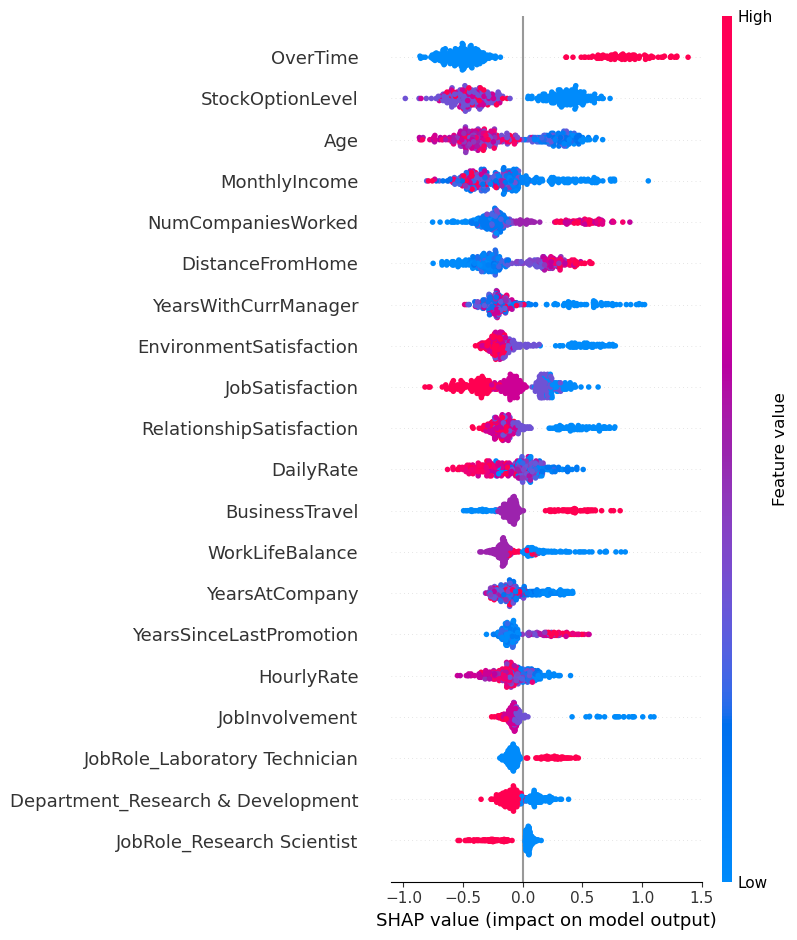

In [76]:
shap.summary_plot(shap_values, X_teste)

In [77]:
probs = modelo_xgboost_ajustado.predict_proba(X_teste)[:, 1]

idx_alto_risco = probs.argmax()
idx_baixo_risco = probs.argmin()

print(f"Índice alto risco: {idx_alto_risco}, probabilidade: {probs[idx_alto_risco]:.3f}")
print(f"Índice baixo risco: {idx_baixo_risco}, probabilidade: {probs[idx_baixo_risco]:.3f}")

Índice alto risco: 10, probabilidade: 0.983
Índice baixo risco: 172, probabilidade: 0.006


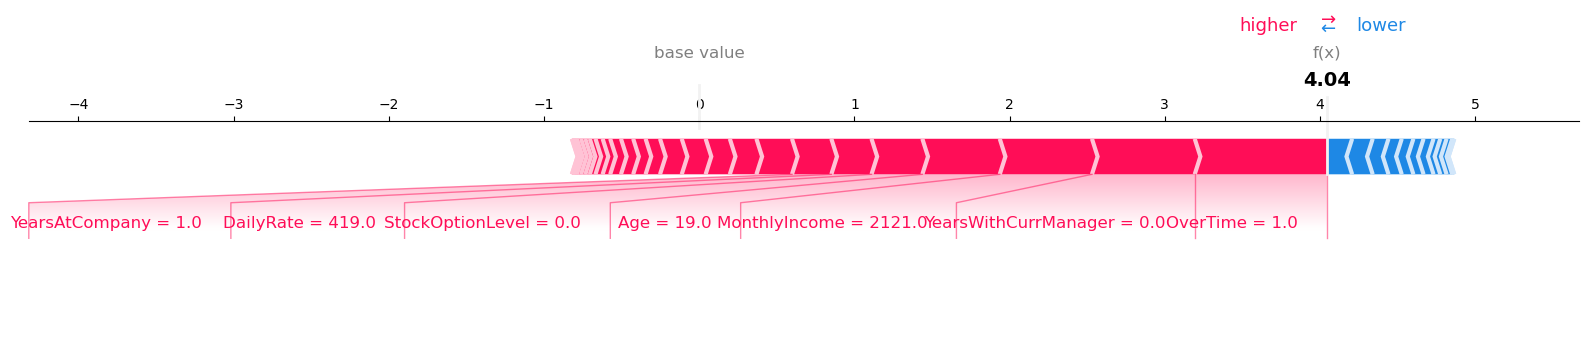

In [78]:
shap.plots.force(shap_values[idx_alto_risco], matplotlib=True)

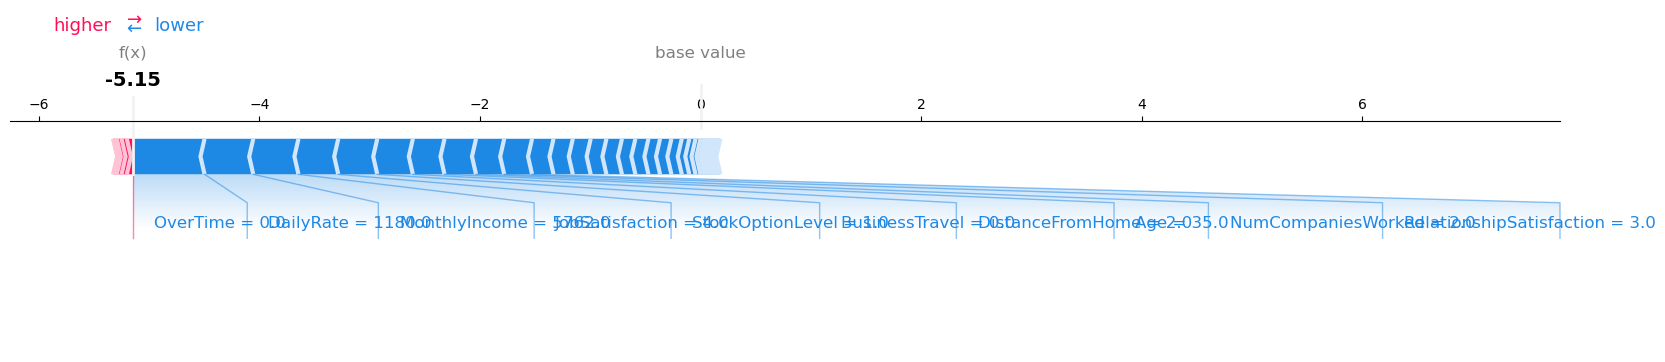

In [79]:
shap.plots.force(shap_values[idx_baixo_risco], matplotlib=True)

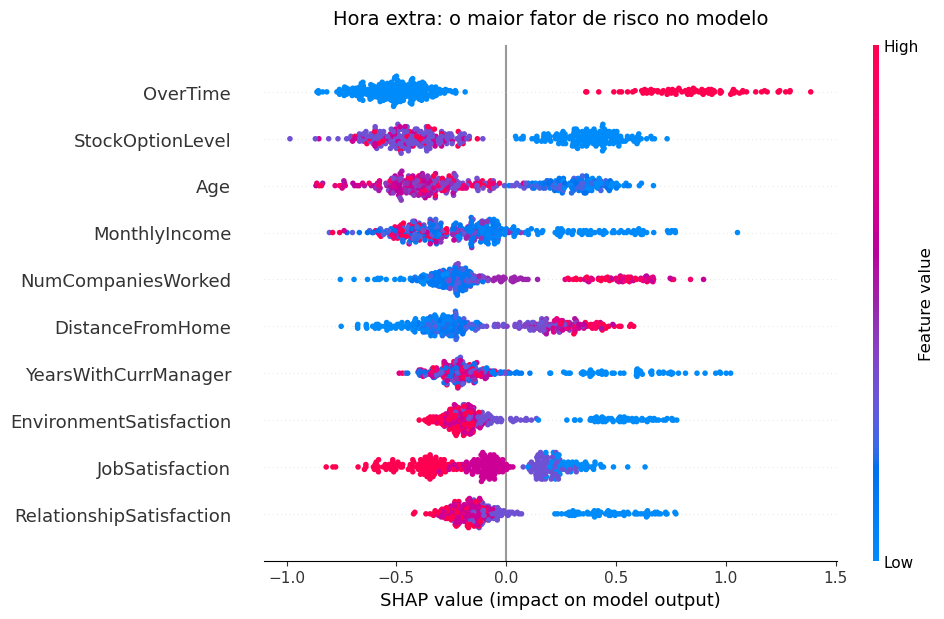

In [80]:
# Exporta o summary plot (imagem usada no README e no post)
shap.summary_plot(shap_values, X_teste, max_display=10, show=False, plot_size=(10, 6))
plt.title("Hora extra: o maior fator de risco no modelo", fontsize=14, pad=15)
plt.savefig('shap_summary_plot.png', bbox_inches='tight', dpi=300)
plt.show()